# Paper 23: Throttle on SPUS, not SPY

v2 screens out banks, alcohol, and weapons, then turns the whole book off because **SPY** is below its 200-day average. That is a process smell. SPUS is the Halal large-cap ETF we already report against. Its 2022 path is not the same as SPY.

Change only `overlay`. Keep next-open fills. Compare:

1. **SPUS 200-day** — same rule, Halal ticker.
2. **SPUS 12-month** — `window=252`.
3. **Either** — on when SPY *or* SPUS is above its 200-day.
4. **Both** — on only when SPY *and* SPUS are above their 200-day.

Scored against **v2 baseline**. Kill rules are frozen in `Research/book-construction-status.md`:

- Train 2022 calendar more than 5pp worse than SPUS
- Train max drawdown worse than SPUS
- Train Calmar below both v2 baseline and SPUS
- Test 2023 calendar more than 15pp worse than v2 baseline

**Variants.** spus-sma, spus-12m, either, both.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "monterey" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError(f"Monterey repo root not found from {start}")

_ROOT = _repo_root()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))
try:
    import monterey  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", f"{_ROOT}[research]"])

from monterey.research import boot, compare, run_book
from monterey.sprints import score_against_baseline
from monterey.spec import BookSpec

rd = boot("paper-23-spus-throttle", start="2019-12-01", end="2026-09-30")
print("snapshot", rd.manifest.get("hash"))
print("v2 hash", BookSpec.load("fcf-sma-v2-baseline").hash())

base = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="23-spus-throttle",
    id="v2",
)


[monterey.data] Loading snapshot ebbbefb35545


        field                   value
       window 2019-12-01 → 2026-09-30
     universe    sp500, point-in-time
      symbols                     631
    snapshots                      85
   price rows                 1147266
    dividends                    9754
filing events                   61274
   halalquant                   0.4.0
snapshot hash            ebbbefb35545
snapshot ebbbefb35545
v2 hash 6ca86844209e


## One trend series at a time


In [2]:
spus_sma = run_book("fcf-sma-v2-baseline", rd, paper="23-spus-throttle", id="spus-sma", overlay={"ticker": "SPUS"})
spus_12m = run_book("fcf-sma-v2-baseline", rd, paper="23-spus-throttle", id="spus-12m", overlay={"ticker": "SPUS", "window": 252})
either = run_book("fcf-sma-v2-baseline", rd, paper="23-spus-throttle", id="either", overlay={"kind": "either_sma", "ticker": "SPUS"})
both = run_book("fcf-sma-v2-baseline", rd, paper="23-spus-throttle", id="both", overlay={"kind": "both_sma", "ticker": "SPUS"})
trials = [spus_sma, spus_12m, either, both]
for book in [base, *trials]:
    print(book.spec.id, book.spec.hash())
    print(" ", dict(book.spec.summary()))


/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw = (px > sma).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:68: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  upper = (px > sma * (1 + band)).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:69: FutureWarning: Downcasting object dtype arrays on .fill

/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw = (px > sma).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:68: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  upper = (px > sma * (1 + band)).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:69: FutureWarning: Downcasting object dtype arrays on .fill

/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw = (px > sma).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:68: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  upper = (px > sma * (1 + band)).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:69: FutureWarning: Downcasting object dtype arrays on .fill

/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw = (px > sma).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:68: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  upper = (px > sma * (1 + band)).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:69: FutureWarning: Downcasting object dtype arrays on .fill

v2 6ca86844209e
  {'book': 'v2', 'hash': '6ca86844209e', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_date', 'cash yield': 'none'}
spus-sma 93aa1a5410d0
  {'book': 'spus-sma', 'hash': '93aa1a5410d0', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPUS 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 b

In [3]:
compare([base, *trials], rd)


,total_return,cagr,volatility,max_drawdown,calmar,sharpe,sortino,turnover,costs_pct,dividends_pct,avg_exposure,switches,hash
book,,,,,,,,,,,,,
v2,1.0644,0.1137,0.1463,-0.2482,0.4582,0.6752,0.8589,4.1653,0.0561,0.0561,0.8032,36.0000,6ca86844209e
spus-sma,1.3292,0.1339,0.1319,-0.2354,0.5688,0.8701,1.1564,3.4568,0.0465,0.0502,0.7187,25.0000,93aa1a5410d0
spus-12m,0.9474,0.1041,0.1321,-0.2972,0.3503,0.6669,0.8746,3.2778,0.0441,0.0479,0.7004,25.0000,88ee6cf0ab21
either,1.1101,0.1174,0.1471,-0.2535,0.4629,0.6945,0.8833,3.9692,0.0534,0.0569,0.8085,32.0000,45bc8949cb77
both,1.2789,0.1302,0.1310,-0.2299,0.5663,0.8502,1.1312,3.6219,0.0487,0.0492,0.7134,29.0000,af53faa25c89
SPUS (total return),2.1167,0.1840,0.2116,-0.3080,0.5975,0.8123,1.0828,NaN,NaN,NaN,NaN,NaN,NaN
SPY (total return),1.6113,0.1533,0.2006,-0.3372,0.4547,0.7140,0.8854,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
for trial in trials:
    verdict = score_against_baseline(trial, base, rd)
    reasons = "; ".join(verdict["reasons"]) or "pass"
    print(trial.spec.id, "KILLED" if verdict["killed"] else "keep", reasons)


spus-sma keep pass
spus-12m KILLED train Calmar below both v2 baseline and SPUS
either KILLED train Calmar below both v2 baseline and SPUS
both keep pass


## Did the switch change?

Count cuts versus v2's 18. Probe crash and bull dates on `regime()`.


In [5]:
import pandas as pd
from monterey.diagnostics.attribution import switch_cost
from monterey.layers import regime
from monterey.spec import BookSpec

spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()
rows = []
for book in [base, *trials]:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    cost = switch_cost(nav, spus)
    rows.append({
        "book": book.spec.id,
        "cuts": cost["cuts"],
        "days_not_invested": cost["days_not_invested"],
        "off_day_loss": cost["off_day_loss"],
        "on_day_missed": cost["on_day_missed"],
        "avg_exposure": float(nav["exposure"].mean()),
    })
display(pd.DataFrame(rows).set_index("book"))

DAYS = ["2020-03-23", "2022-06-30", "2023-06-30", "2024-12-31"]
SPECS = {
    "v2": BookSpec.load("fcf-sma-v2-baseline"),
    "spus-sma": BookSpec.load("fcf-sma-v2-baseline").replace(id="spus-sma", overlay={"ticker": "SPUS"}),
    "spus-12m": BookSpec.load("fcf-sma-v2-baseline").replace(id="spus-12m", overlay={"ticker": "SPUS", "window": 252}),
    "either": BookSpec.load("fcf-sma-v2-baseline").replace(id="either", overlay={"kind": "either_sma", "ticker": "SPUS"}),
    "both": BookSpec.load("fcf-sma-v2-baseline").replace(id="both", overlay={"kind": "both_sma", "ticker": "SPUS"}),
}
probe = []
for name, spec in SPECS.items():
    frame = regime(rd, spec, rd.sessions)
    for day in DAYS:
        idx = day if day in frame.index else pd.Timestamp(day)
        if idx not in frame.index:
            continue
        row = frame.loc[idx]
        probe.append({"book": name, "day": day, "raw": bool(row["raw"]), "on": bool(row["on"]), "exposure": float(row["exposure"])})
pd.DataFrame(probe)


,cuts,days_not_invested,off_day_loss,on_day_missed,avg_exposure
book,,,,,
v2,18,352,-0.2591,0.4449,0.8032
spus-sma,12,489,-0.1696,0.2127,0.7187
spus-12m,12,520,-0.1881,0.2670,0.7004
either,16,341,-0.2567,0.3790,0.8085
both,14,500,-0.1724,0.2707,0.7134


/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  raw = (px > sma).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:68: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  upper = (px > sma * (1 + band)).reindex(sessions).ffill().fillna(False).astype(bool)
/Users/raoabdul/Documents/Development/Monterey-Finance/monterey/layers/overlay.py:69: FutureWarning: Downcasting object dtype arrays on .fill

,book,day,raw,on,exposure
0,v2,2020-03-23,False,False,0.0000
1,v2,2022-06-30,False,False,0.0000
2,v2,2023-06-30,True,True,1.0000
3,v2,2024-12-31,True,True,1.0000
4,spus-sma,2020-03-23,False,False,0.0000
5,spus-sma,2022-06-30,False,False,0.0000
6,spus-sma,2023-06-30,True,True,1.0000
7,spus-sma,2024-12-31,True,True,1.0000
8,spus-12m,2020-03-23,False,False,0.0000
9,spus-12m,2022-06-30,False,False,0.0000


## Path, not just the scorecard


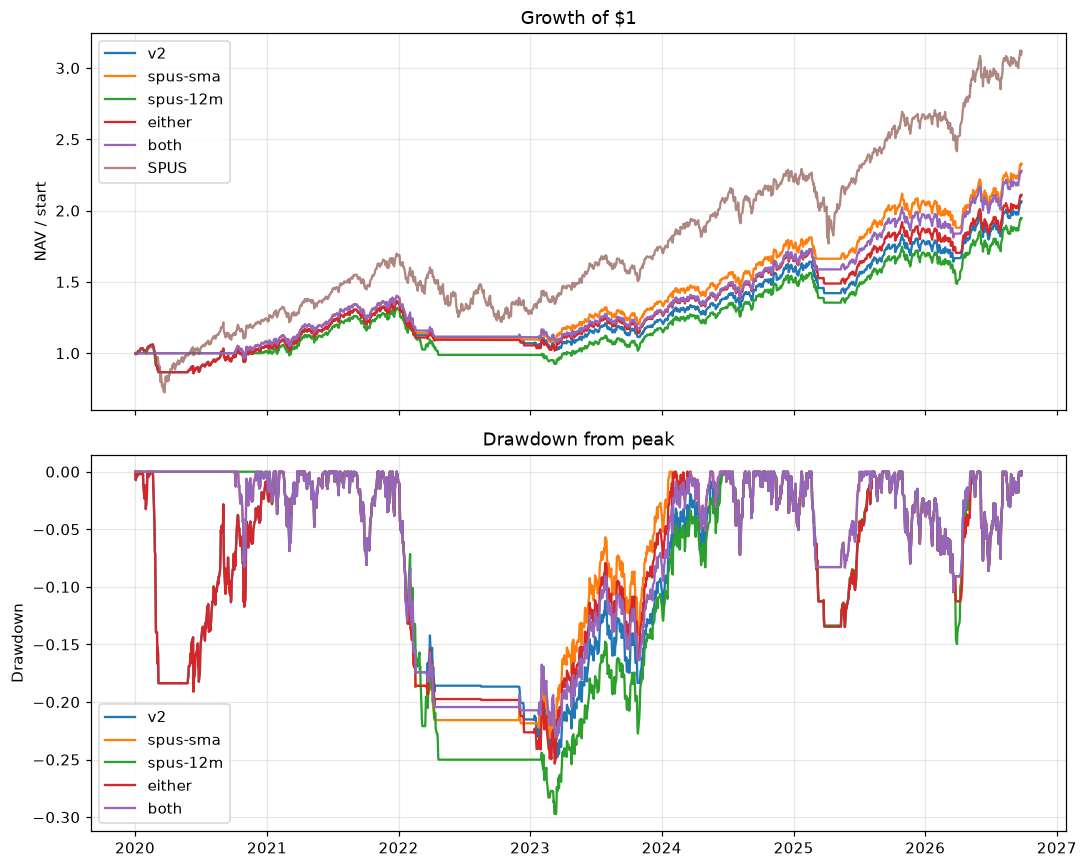

wrote figures/nav-and-drawdown.png


In [6]:
import matplotlib.pyplot as plt
from monterey.diagnostics import yearly

books = [base, *trials]
figures = Path("figures")
figures.mkdir(exist_ok=True)
spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for book in books:
    nav = book.nav_series()
    axes[0].plot(nav.index, nav / nav.iloc[0], label=book.spec.id)
    dd = nav / nav.cummax() - 1.0
    axes[1].plot(dd.index, dd, label=book.spec.id)
axes[0].plot(spus.index, spus / spus.iloc[0], label="SPUS", alpha=0.7)
axes[0].set_title("Growth of $1")
axes[0].set_ylabel("NAV / start")
axes[0].legend()
axes[1].set_title("Drawdown from peak")
axes[1].set_ylabel("Drawdown")
axes[1].legend()
fig.tight_layout()
fig.savefig(figures / "nav-and-drawdown.png", dpi=140)
plt.show()
print("wrote", figures / "nav-and-drawdown.png")


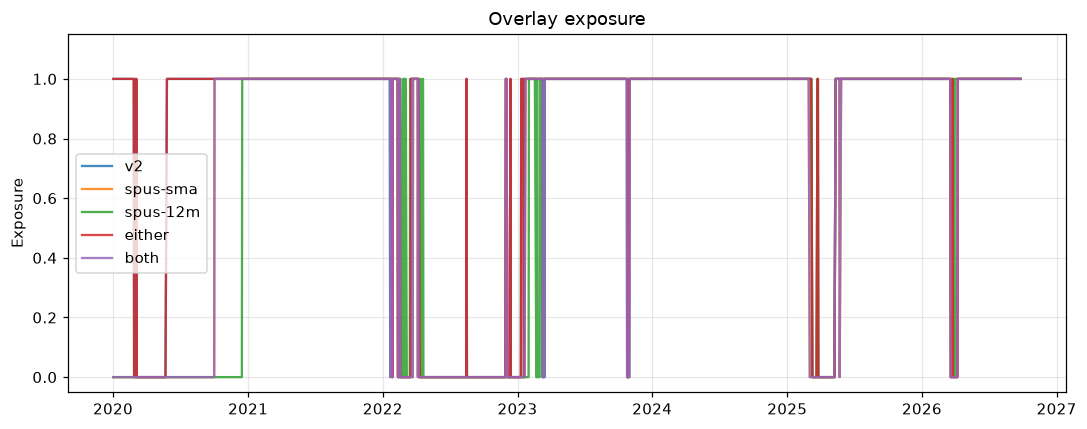

wrote figures/exposure.png


In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for book in books:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    ax.plot(nav["date"], nav["exposure"], label=book.spec.id, alpha=0.85)
ax.set_title("Overlay exposure")
ax.set_ylabel("Exposure")
ax.set_ylim(-0.05, 1.15)
ax.legend()
fig.tight_layout()
fig.savefig(figures / "exposure.png", dpi=140)
plt.show()
print("wrote", figures / "exposure.png")


,v2,spus-sma,spus-12m,either,both,SPUS
year,,,,,,
2020,0.0528,0.0830,0.0165,0.0528,0.0830,0.2399
2021,0.2831,0.2836,0.2836,0.2831,0.2836,0.3562
2022,-0.2080,-0.2114,-0.2433,-0.2193,-0.2000,-0.2276
2023,0.1525,0.2414,0.1884,0.2241,0.1687,0.3420
2024,0.2741,0.2745,0.2748,0.2744,0.2745,0.2649
2025,0.1250,0.1778,0.1263,0.1250,0.1775,0.1978
2026,0.1681,0.1403,0.1560,0.1401,0.1684,0.1802


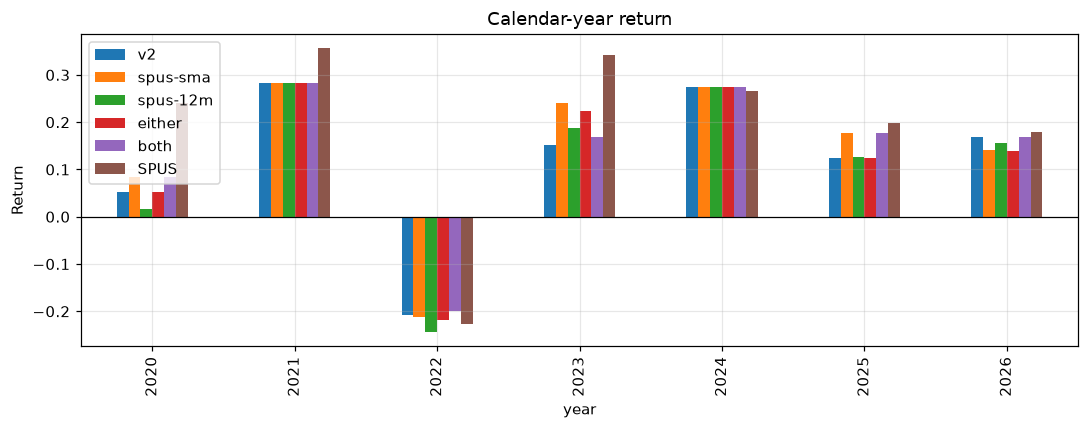

wrote figures/calendar-returns.png


In [8]:
calendar = pd.concat(
    {book.spec.id: yearly(book.nav_series())["return"] for book in books},
    axis=1,
)
calendar["SPUS"] = yearly(spus)["return"]
display(calendar)

ax = calendar.plot(kind="bar", figsize=(10, 4))
ax.set_title("Calendar-year return")
ax.set_ylabel("Return")
ax.axhline(0, color="black", lw=0.8)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figures / "calendar-returns.png", dpi=140)
plt.show()
print("wrote", figures / "calendar-returns.png")


## Conclusion

**Would we run this?** SPUS as the 200-day series is the clean process fix, and on this sample it is also a better score. Calmar rises from **0.46 to 0.57**, cuts fall from **18 to 12**, max drawdown is **−23.5%** versus −24.8%. It passes the kill rules. Requiring **both** SPY and SPUS on is almost the same score (Calmar 0.57, DD −23.0%) with 14 cuts. A 12-month SPUS line and “either index on” fail train Calmar.

**What we asked.** We screen out banks, alcohol, and weapons, then turn the book off because **SPY** is below its average. This paper kept the same 200-day on/off mechanics and next-open fills, and only changed the trend series: SPUS 200-day, SPUS 252-day, either SPY or SPUS, both SPY and SPUS.

**What happened.**

- SPUS-SMA is quieter and kinder on the off days. Off-day fund loss −17% versus v2 −26%. Missed SPUS on the way back in +21% versus +45%. Days not fully invested rise (489 versus 352) because SPUS stayed weak longer — and 2023 is the payoff: **+24.1%** versus v2 **+15.3%**. 2022 is almost unchanged (−21.1% versus −20.8%).
- Both-must-be-on is a close cousin (2022 −20.0%, 2023 +16.9%, Calmar 0.57). Either-can-be-on stays closest to v2 and is **killed**. The 12-month SPUS window is slower and **killed** (DD −29.7%).
- SPUS Calmar is still 0.60. A Halal trend series does not close the whole gap. It does make “we throttle on our own benchmark” an honest sentence.

**What this means for the fund.** Using SPY was a convenience, not a proven cleaner crash signal. On 2020–26, SPUS 200-day is quieter and higher Calmar. Pair it with paper 21 if we still sit in cash on the extra off days. Do not add a 12-month rule or an either-or gate from this notebook.

**Live rule.** The scored v2 hash can stay on SPY so older papers compare. For a product overlay, **`overlay.ticker = SPUS`** is the candidate to take to the board. `both_sma` is a backup, not a second live switch. Do not promote `window=252` or `either_sma`.
